<a href="https://colab.research.google.com/github/rachnaa-s/ML-lab-Weather-prediction/blob/main/IDS_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

train_df = pd.read_csv(
    "/content/KDDTrain+.csv",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    "/content/KDDTest+.csv",
    header=None,
    names=columns
)

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

display(train_df.head())

Training data: (125973, 43)
Testing data: (22543, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [ ]:
X_train = train_df.drop(columns=["label", "difficulty"])
X_test = test_df.drop(columns=["label", "difficulty"])

y_train = (
    train_df["label"].str.strip() != "normal"
).astype(int)

y_test = (
    test_df["label"].str.strip() != "normal"
).astype(int)

categorical_cols = ["protocol_type", "service", "flag"]

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
]

preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    ),
    ("numeric", "passthrough", numeric_cols)
])

print("Training records:", len(X_train))
print("Normal records:", (y_train == 0).sum())
print("Attack records:", (y_train == 1).sum())

Training records: 125973
Normal records: 67343
Attack records: 58630


In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

trained_models = {}
results = {}

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    print("Training:", name)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model
    results[name] = accuracy

    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Normal", "Attack"],
        zero_division=0
    ))

print("Model comparison:", results)

Training: Decision Tree
Accuracy: 80.99%
              precision    recall  f1-score   support

      Normal       0.71      0.96      0.81      9710
      Attack       0.96      0.70      0.81     12833

    accuracy                           0.81     22543
   macro avg       0.83      0.83      0.81     22543
weighted avg       0.85      0.81      0.81     22543

Training: Random Forest
Accuracy: 77.51%
              precision    recall  f1-score   support

      Normal       0.66      0.97      0.79      9710
      Attack       0.97      0.62      0.76     12833

    accuracy                           0.78     22543
   macro avg       0.82      0.80      0.77     22543
weighted avg       0.84      0.78      0.77     22543

Model comparison: {'Decision Tree': 0.8099188218072129, 'Random Forest': 0.7750964822783125}


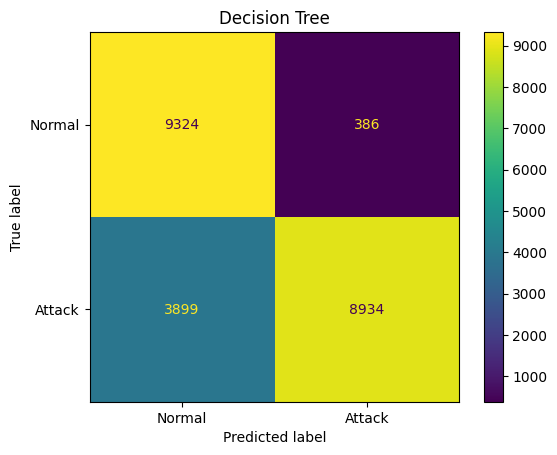

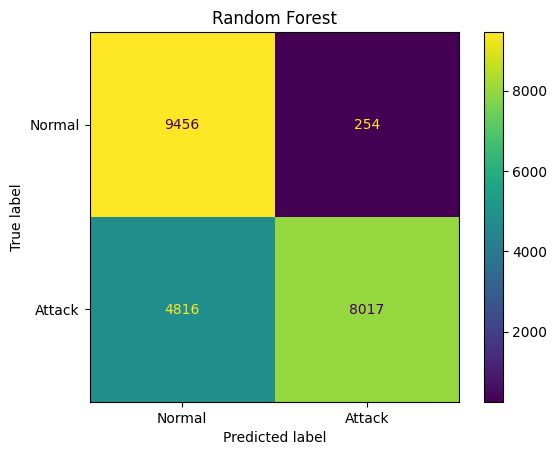

In [ ]:
for name, model in trained_models.items():
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Attack"]
    ).plot()

    plt.title(name)
    plt.show()

In [ ]:
best_name = max(results, key=results.get)
best_model = trained_models[best_name]

joblib.dump(best_model, "/content/ids_model.pkl")

print("Selected model:", best_name)
print("Saved as ids_model.pkl")

Selected model: Decision Tree
Saved as ids_model.pkl


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    print(f"\n===== {name} =====")

    print(classification_report(
        y_test,
        predictions,
        target_names=["Normal", "Attack"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


===== Decision Tree =====
              precision    recall  f1-score   support

      Normal       0.71      0.96      0.81      9710
      Attack       0.96      0.70      0.81     12833

    accuracy                           0.81     22543
   macro avg       0.83      0.83      0.81     22543
weighted avg       0.85      0.81      0.81     22543

Confusion Matrix:
[[9324  386]
 [3899 8934]]

===== Random Forest =====
              precision    recall  f1-score   support

      Normal       0.66      0.97      0.79      9710
      Attack       0.97      0.62      0.76     12833

    accuracy                           0.78     22543
   macro avg       0.82      0.80      0.77     22543
weighted avg       0.84      0.78      0.77     22543

Confusion Matrix:
[[9456  254]
 [4816 8017]]


In [ ]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]

if prediction == 0:
    print("NORMAL TRAFFIC")
else:
    print("POTENTIAL INTRUSION")

print("Actual:",
      "NORMAL" if y_test.iloc[0] == 0 else "ATTACK")

POTENTIAL INTRUSION
Actual: ATTACK
